In [1]:
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from matplotlib import pyplot as plt
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print("device: ", device)


def set_seed(seed: int):
    # random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=False)

PyTorch version: 2.14.0+cu126
CUDA available: True
device:  cuda


### Гиперпараметры

In [3]:
SEED = 42
set_seed(SEED)

IMAGE_SIZE = 100
TRAIN_PATH = Path("fruits/Training")
TEST_PATH = Path("fruits/Test")

BATCH_SIZE = 32
VAL_FRACTION = 0.1
EPOCHS = 10
LR = 4e-4
DROPOUT = 0.3

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

### Аугментации + Dataset (ImageFolder) + DalaLoader

In [4]:
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(
        degrees=10,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05),
        fill=(255, 255, 255),
    ),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.08,
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

In [5]:
train_raw_dataset = datasets.ImageFolder(root=TRAIN_PATH, transform=train_transform)
val_raw_dataset = datasets.ImageFolder(root=TRAIN_PATH, transform=test_transform)
test_dataset = datasets.ImageFolder(root=TEST_PATH, transform=test_transform)

all_indices = np.arange(len(train_raw_dataset))
all_targets = np.asarray(train_raw_dataset.targets)
train_indices, val_indices = train_test_split(
    all_indices,
    test_size=VAL_FRACTION,
    random_state=SEED,
    stratify=all_targets,
)

train_dataset = Subset(train_raw_dataset, train_indices.tolist())
val_dataset = Subset(val_raw_dataset, val_indices.tolist())

In [6]:
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, pin_memory=True
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, pin_memory=True
)

In [7]:
class_names = train_raw_dataset.classes
num_classes = len(class_names)

print(f"Количество классов: {num_classes}")
print(f"Train: {len(train_dataset):,} изображений")
print(f"Validation: {len(val_dataset):,} изображений")
print(f"Test: {len(test_dataset):,} изображений")
print(f"Пример классов: {class_names[:10]}")

Количество классов: 278
Train: 134,518 изображений
Validation: 14,947 изображений
Test: 49,785 изображений
Пример классов: ['Almonds 1', 'Apple 10', 'Apple 11', 'Apple 12', 'Apple 13', 'Apple 14', 'Apple 17', 'Apple 18', 'Apple 19', 'Apple 20']


### Создание модели (VGG-16)
Имеет 5 блоков с количеством свёрток в них: 2, 2, 3, 3, 3. Каждая свёртка состоит из Conv2d(3x3) -> BatchNorm -> ReLU. После каждого блока используется MaxPooling. После свёрточной части применяется AdaptiveAvgPool2d((1, 1)), поэтому классификационная голова получает 512 признаков независимо от размера входа. Голова состоит из 3 полносвязных слоёв с ReLU + Dropout.

In [8]:
class Light_VGG16(nn.Module):
    @staticmethod
    def conv_block(in_channels: int, out_channels: int):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

    def __init__(
            self,
            num_classes: int,
            in_channels: int = 3,
            dropout: float = 0.5
    ):
        super().__init__()

        self.features = nn.Sequential(
            self.conv_block(in_channels, 32),
            self.conv_block(32, 64),
            self.conv_block(64, 128),
            self.conv_block(128, 256),
        )
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout),
            nn.Linear(256, num_classes),
        )

        self._init_weights()

    def _init_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(module, nn.BatchNorm2d):
                nn.init.ones_(module.weight)
                nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Linear):
                nn.init.normal_(module.weight, mean=0.0, std=0.01)
                nn.init.zeros_(module.bias)

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        return self.classifier(x)

### Обучение модели

In [9]:
@torch.no_grad()
def evaluate(model, criterion, loader, num_classes):
    model.eval()

    loss_sum = 0.0
    seen = 0
    all_labels = []
    all_predictions = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True, dtype=torch.float32)
        labels = labels.to(device, non_blocking=True, dtype=torch.long)

        logits = model(images)
        loss = criterion(logits, labels)
        predictions = logits.argmax(dim=1)

        batch_size = labels.size(0)
        loss_sum += loss.item() * batch_size
        seen += batch_size
        all_labels.extend(labels.cpu().numpy().tolist())
        all_predictions.extend(predictions.cpu().numpy().tolist())

    mean_loss = loss_sum / seen
    accuracy = float(np.mean(np.asarray(all_labels) == np.asarray(all_predictions)))
    f1_macro = f1_score(
        all_labels,
        all_predictions,
        labels=np.arange(num_classes),
        average="macro"
    )

    return mean_loss, float(f1_macro), accuracy

In [10]:
def train(model, optimizer, criterion, scheduler,
          train_loader, val_loader, epochs,
          n_early_stopping: int = 5,
          verbose: bool = True,
          save_path: str | None = "best_model.pth"):
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_f1_macro": [],
        "val_f1_macro": [],
        "train_accuracy": [],
        "val_accuracy": [],
        "lr": [],
    }

    best_val_f1 = -1.0
    epochs_no_improve = 0

    for epoch in range(epochs):
        # train
        model.train()

        time_epoch_start = time.time()
        current_lr = optimizer.param_groups[0]["lr"]

        train_loss_sum = 0.0
        train_seen = 0
        train_labels = []
        train_predictions = []

        for images, labels in train_loader:
            images = images.to(device, non_blocking=True, dtype=torch.float32)
            labels = labels.to(device, non_blocking=True, dtype=torch.long)

            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)
            train_loss_sum += loss.item() * batch_size
            train_seen += batch_size

            predictions = logits.detach().argmax(dim=1)
            train_labels.extend(labels.detach().cpu().numpy().tolist())
            train_predictions.extend(predictions.cpu().numpy().tolist())

        train_loss = train_loss_sum / train_seen
        train_accuracy = float(
            np.mean(np.asarray(train_labels) == np.asarray(train_predictions))
        )
        train_f1_macro = f1_score(
            train_labels,
            train_predictions,
            labels=np.arange(num_classes),
            average="macro"
        )

        val_loss, val_f1_macro, val_accuracy = evaluate(
            model, criterion, val_loader, num_classes=num_classes
        )

        history["train_loss"].append(float(train_loss))
        history["val_loss"].append(float(val_loss))
        history["train_f1_macro"].append(float(train_f1_macro))
        history["val_f1_macro"].append(float(val_f1_macro))
        history["train_accuracy"].append(float(train_accuracy))
        history["val_accuracy"].append(float(val_accuracy))
        history["lr"].append(float(current_lr))

        if verbose:
            print(
                f"[{epoch + 1:02d}/{epochs}] "
                f"loss={train_loss:.4f}/{val_loss:.4f}  "
                f"f1_macro={train_f1_macro:.4f}/{val_f1_macro:.4f}  "
                f"accuracy={train_accuracy:.4f}/{val_accuracy:.4f}  "
                f"time={time.time() - time_epoch_start:.1f}s  "
                f"lr={current_lr:.3g}"
            )

        # early stopping
        if val_f1_macro > best_val_f1:
            best_val_f1 = val_f1_macro
            epochs_no_improve = 0
            # сохраняем веса на диск
            if save_path is not None:
                torch.save(model.state_dict(), save_path)
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= n_early_stopping:
                if verbose:
                    print(
                        f"early stop on epoch {epoch + 1}, "
                        f"best best_val_f1={best_val_f1:.4f}"
                    )
                break

        # обновляем lr согласно логике scheduler
        scheduler.step(val_f1_macro)

    # возвращаем модели её лучшие веса
    if save_path is not None and Path(save_path).exists():
        model.load_state_dict(torch.load(save_path, map_location=device, weights_only=True))
        if verbose:
            print(f"loaded best state (best_val_f1={best_val_f1:.4f})")

    return history

### Запуск обучения

In [11]:
model = Light_VGG16(num_classes=num_classes, dropout=DROPOUT).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-3)
scheduler = ReduceLROnPlateau(optimizer, mode="max", patience=2, factor=0.5)

history = train(
    model, optimizer, criterion, scheduler,
    train_loader, val_loader, epochs=EPOCHS, save_path=None
)

[01/10] loss=1.2442/0.2042  f1_macro=0.6891/0.9381  accuracy=0.6882/0.9437  time=243.6s  lr=0.0004
[02/10] loss=0.2665/0.1561  f1_macro=0.9180/0.9487  accuracy=0.9172/0.9515  time=240.1s  lr=0.0004
[03/10] loss=0.1589/0.0848  f1_macro=0.9492/0.9698  accuracy=0.9487/0.9688  time=233.5s  lr=0.0004
[04/10] loss=0.1130/0.0264  f1_macro=0.9640/0.9918  accuracy=0.9639/0.9920  time=231.4s  lr=0.0004
[05/10] loss=0.0863/0.0389  f1_macro=0.9720/0.9888  accuracy=0.9720/0.9884  time=233.5s  lr=0.0004
[06/10] loss=0.0701/0.0200  f1_macro=0.9773/0.9930  accuracy=0.9772/0.9942  time=230.4s  lr=0.0004
[07/10] loss=0.0588/0.0321  f1_macro=0.9805/0.9900  accuracy=0.9806/0.9900  time=237.7s  lr=0.0004
[08/10] loss=0.0489/0.0193  f1_macro=0.9843/0.9941  accuracy=0.9844/0.9938  time=232.2s  lr=0.0004
[09/10] loss=0.0411/0.0113  f1_macro=0.9868/0.9966  accuracy=0.9869/0.9975  time=232.5s  lr=0.0004
[10/10] loss=0.0399/0.0223  f1_macro=0.9874/0.9917  accuracy=0.9874/0.9926  time=234.2s  lr=0.0004


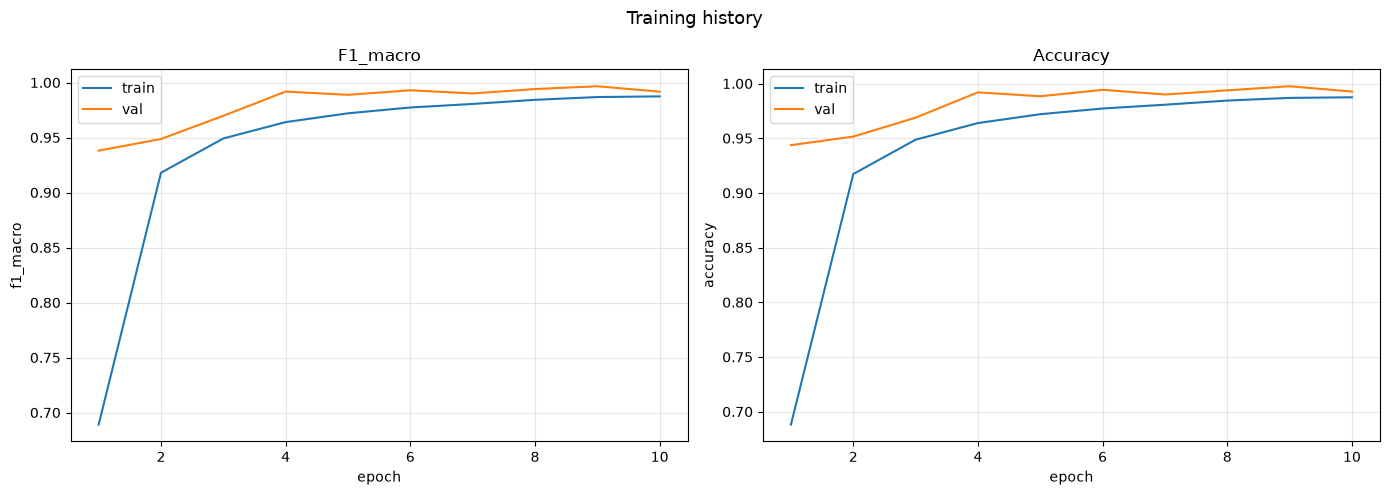

In [12]:
def plot_history(history):
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs, history["train_f1_macro"], label="train", color="tab:blue")
    axes[0].plot(epochs, history["val_f1_macro"], label="val", color="tab:orange")
    axes[0].set_title("F1_macro")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("f1_macro")
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    axes[1].plot(epochs, history["train_accuracy"], label="train", color="tab:blue")
    axes[1].plot(epochs, history["val_accuracy"], label="val", color="tab:orange")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("accuracy")
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    fig.suptitle("Training history", fontsize=13)
    plt.tight_layout()
    plt.show()


plot_history(history)

### Проверка на test

In [13]:
test_loss, test_f1_macro, test_accuracy = evaluate(
    model,
    criterion,
    test_loader,
    num_classes=num_classes
)

print("\nРезультаты собственной CNN (облегчённая VGG-16) на test:")
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test F1_macro: {test_f1_macro:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")


Результаты собственной CNN (облегчённая VGG-16) на test:
Test Loss:     0.3350
Test F1_macro: 0.9752
Test Accuracy: 0.9797


### Использование предобученной модели (ResNet)
Будут использоваться всё те же аугментации, Dataloader и методы evaluate/train. Под замену идут только сама модель и запуск обучения

In [14]:
from torchvision.models import resnet18, ResNet18_Weights


class StolenResNet18(nn.Module):
    def __init__(
            self,
            num_classes: int,
            dropout: float = 0.3
    ):
        super().__init__()

        # загружаем предобученную ResNet-18
        self.backbone = resnet18(weights=ResNet18_Weights.DEFAULT)
        # запоминаем количество признаков перед классификатором
        in_features = self.backbone.fc.in_features
        # удаляем оригинальную классификационную голову
        self.backbone.fc = nn.Identity()
        # замораживаем все параметры ResNet
        for param in self.backbone.parameters():
            param.requires_grad = False
        # создаём новую классификационную голову
        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(int(in_features), num_classes)
        )

    def train(self, mode: bool = True):
        super().train(mode)
        # не обновляем BatchNorm статистики в backbone
        self.backbone.eval()
        return self

    def forward(self, x):
        # не вычисляем градиенты для обученной части
        with torch.no_grad():
            features = self.backbone(x)
        return self.classifier(features)

In [15]:
model_resnet = StolenResNet18(num_classes=num_classes, dropout=DROPOUT).to(device)
criterion_resnet = nn.CrossEntropyLoss()
optimizer_resnet = torch.optim.AdamW(
    model_resnet.classifier.parameters(),
    lr=LR,
    weight_decay=1e-4
)
scheduler_resnet = ReduceLROnPlateau(
    optimizer_resnet,
    mode="max",
    patience=2,
    factor=0.5
)

history_resnet = train(
    model_resnet, optimizer_resnet, criterion_resnet, scheduler_resnet,
    train_loader, val_loader, epochs=EPOCHS, save_path=None
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\116wi/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 66.6MB/s]


[01/10] loss=0.8859/0.2299  f1_macro=0.8043/0.9473  accuracy=0.7978/0.9431  time=199.6s  lr=0.0004
[02/10] loss=0.2535/0.1334  f1_macro=0.9335/0.9662  accuracy=0.9286/0.9649  time=204.4s  lr=0.0004
[03/10] loss=0.1892/0.0962  f1_macro=0.9465/0.9745  accuracy=0.9415/0.9729  time=181.9s  lr=0.0004
[04/10] loss=0.1634/0.0776  f1_macro=0.9522/0.9802  accuracy=0.9478/0.9783  time=182.4s  lr=0.0004
[05/10] loss=0.1493/0.0739  f1_macro=0.9546/0.9794  accuracy=0.9504/0.9776  time=182.2s  lr=0.0004
[06/10] loss=0.1402/0.0589  f1_macro=0.9564/0.9837  accuracy=0.9520/0.9821  time=185.8s  lr=0.0004
[07/10] loss=0.1325/0.0597  f1_macro=0.9589/0.9830  accuracy=0.9549/0.9807  time=195.6s  lr=0.0004
[08/10] loss=0.1287/0.0563  f1_macro=0.9596/0.9833  accuracy=0.9558/0.9816  time=183.9s  lr=0.0004
[09/10] loss=0.1216/0.0462  f1_macro=0.9617/0.9876  accuracy=0.9578/0.9857  time=201.7s  lr=0.0004
[10/10] loss=0.1191/0.0515  f1_macro=0.9619/0.9844  accuracy=0.9577/0.9833  time=215.6s  lr=0.0004


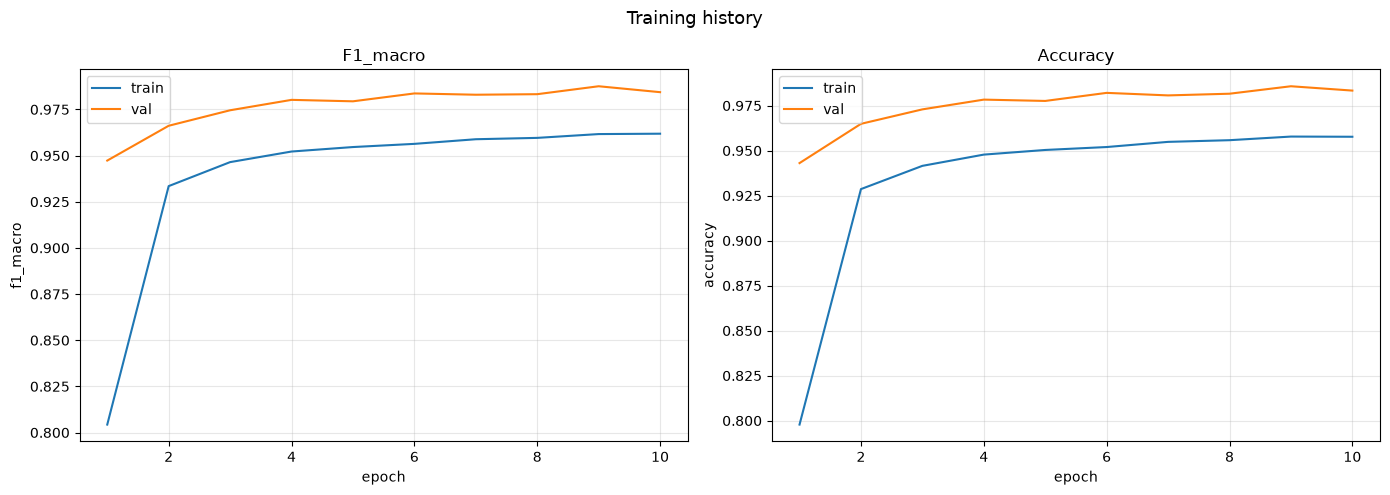

In [16]:
plot_history(history_resnet)

In [17]:
test_loss, test_f1_macro, test_accuracy = evaluate(
    model_resnet,
    criterion_resnet,
    test_loader,
    num_classes=num_classes
)

print("\nРезультаты ResNet-18 с изменённой головой на test:")
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test F1_macro: {test_f1_macro:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")


Результаты ResNet-18 с изменённой головой на test:
Test Loss:     0.3429
Test F1_macro: 0.9508
Test Accuracy: 0.9541


### Сравнение результатов обоих моделей

In [19]:
def count_parameters(model):
    total_params = sum(
        p.numel() for p in model.parameters()
    )
    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )
    frozen_params = total_params - trainable_params

    return total_params, trainable_params, frozen_params


models = {
    "Light VGG16": model,
    "Pretrained ResNet18 ": model_resnet,
}

for name, model_instance in models.items():
    total, trainable, frozen = count_parameters(model_instance)

    print(f"\n{name}:")
    print(f"Total parameters:     {total:,}")
    print(f"Trainable parameters: {trainable:,}")
    print(f"Frozen parameters:    {frozen:,}")
    print(f"Trainable percentage: {trainable / total * 100:.2f}%")


Light VGG16:
Total parameters:     1,244,662
Trainable parameters: 1,244,662
Frozen parameters:    0
Trainable percentage: 100.00%

Pretrained ResNet18 :
Total parameters:     11,319,126
Trainable parameters: 142,614
Frozen parameters:    11,176,512
Trainable percentage: 1.26%


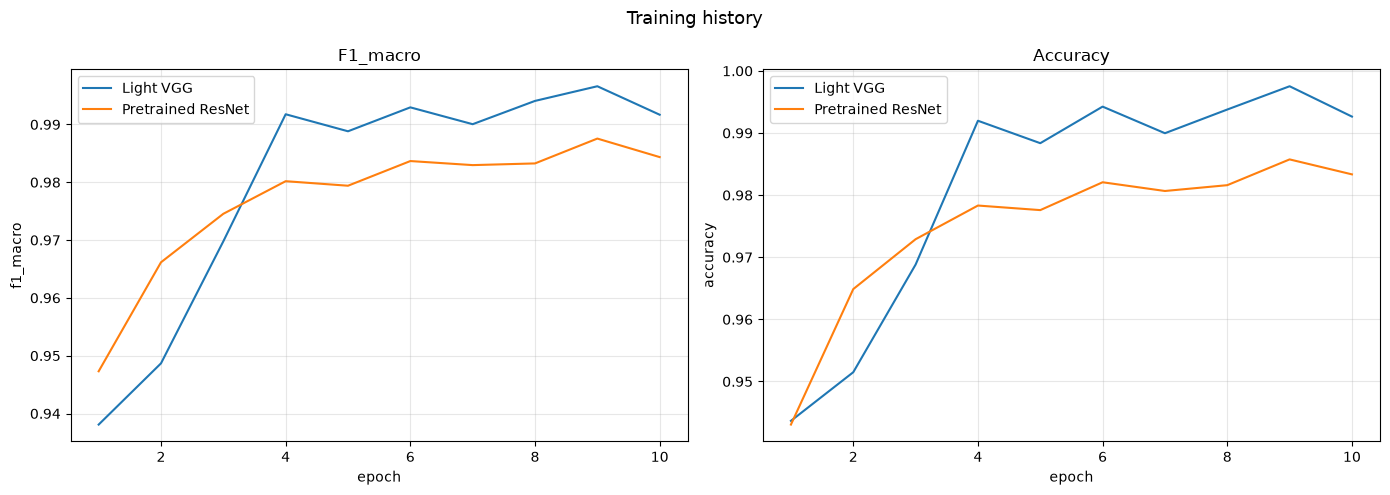

In [20]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history["val_f1_macro"], label="Light VGG", color="tab:blue")
axes[0].plot(epochs, history_resnet["val_f1_macro"], label="Pretrained ResNet", color="tab:orange")
axes[0].set_title("F1_macro")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("f1_macro")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(epochs, history["val_accuracy"], label="Light VGG", color="tab:blue")
axes[1].plot(epochs, history_resnet["val_accuracy"], label="Pretrained ResNet", color="tab:orange")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].grid(alpha=0.3)
axes[1].legend()

fig.suptitle("Training history", fontsize=13)
plt.tight_layout()
plt.show()

### Итоговые выводы

1) Pretrained ResNet имеет в ~9 раз больше параметров, чем VGG, а также в нём есть residual connections, которые лучше позволяют проходить градиентам через конволюционные слои.
2) ResNet изначально обучался на ImageNet, а там сильно другой тип данных - классы не ограничиваются фруктами или ягодами, а также в нём не просто белый фон. Поэтому VGG, который полностью обучался на Fruit-360 имеет преимущество, т.к. лучше знаком с целевой выборкой. Также все веса в конволюционных слоях ResNet были полностью заморожены, поэтому как-то дообучиться для такого типа данных модель не могла.
3) Смотря на графики выше, можно определить, что на первых эпохах обучения метрики лучше на ResNet, т.к. он изначально был обучен и лишь обучал свою голову. Затем лидировать стал VGG, т.к. он уже достаточно обучился для такого типа данных.
4) F1_macro(VGG) = 0.9752, F1_macro(ResNet) = 0.9508. В результате лучшую метрику показывает VGG. Это больше всего объясняется тем, что в датасете Fruit-360 очень много данных (для train ~150k), а также данные сами по себе легко различимы - "фрукт" находится ровно по центру, фон всегда белый, есть много похожих изображений (буквально для каждого фрукта есть фотка с поворотом на 1 градус). Таким образом, выгоднее было обучить свою модель, хоть и с меньшими весами.
5) Честно говоря удивительно, что ResNet получил такой большой скор, хотя он обучался совершенно на других данных и он не дообучался.